In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [6]:
x, y = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)

In [7]:
df = pd.DataFrame(x, columns=['Feature 1', 'Feature 2'])

In [8]:
df

,Feature 1,Feature 2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [9]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(df)

In [10]:
k_range = range(1, 11)
inertia = []


In [11]:
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

In [12]:
inertia

[1000.0000000000001,
 297.89541410517216,
 11.575484723104978,
 9.752067977356841,
 8.257175272446283,
 6.9175773204167985,
 6.334755391595287,
 5.70417717790143,
 5.060234133532076,
 4.762361898130397]

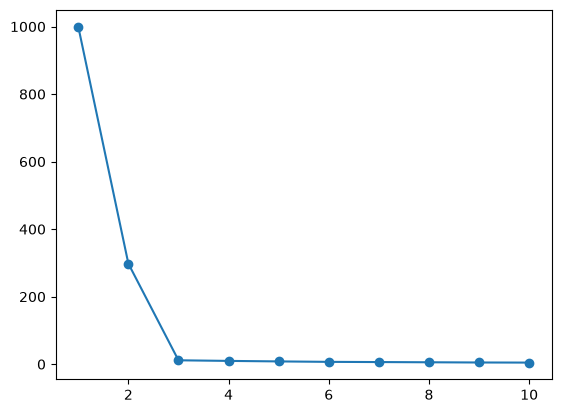

In [13]:
plt.plot(k_range, inertia, marker='o')

In [14]:
kmeans_final= KMeans(n_clusters=3, random_state=42)

In [15]:
clusters = kmeans_final.fit_predict(x_scaled)

In [16]:
df['Cluster'] = clusters

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

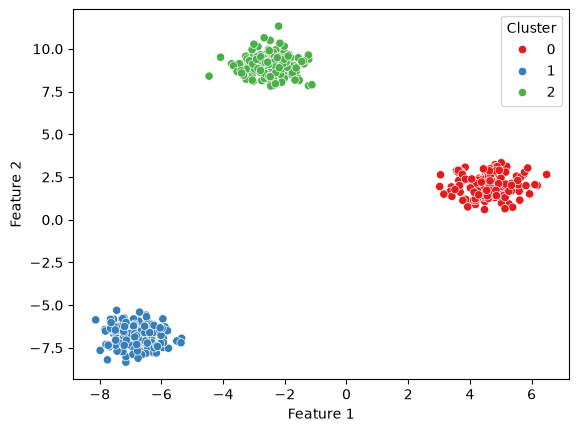

In [17]:
sns.scatterplot(data=df,x=df['Feature 1'],y=df['Feature 2'],hue=df['Cluster'],palette='Set1')